# Options pricing on NIFTY 50: Black-Scholes, binomial trees and the Greeks

This notebook builds European and American option pricers, checks them against textbook values and numerical identities, and applies them to the NSE NIFTY 50 option chain at the close of Friday 30-Oct-2026.

- Code lives in `src/options/` and is imported below. Data is in `data/raw/` (NSE option-chain JSON snapshots and Yahoo Finance index history), so the notebook runs offline.
- Valuation at the 30-Oct-2026 close. Time to expiry T = calendar days / 365. Risk-free rate r = ln(1.0593) = 5.761% p.a. continuous, from the 91-day T-bill cut-off yield of 5.93% (RBI auction of 28-Oct-2026).
- The last section runs `src/run_all.py`, which writes every figure in `figures/` and every CSV in `outputs/`.

Contents: 1 Models, 2 Validation, 3 Market data, 4 Implied forwards, 5 Implied vols and the smile, 6 Term structure and India VIX, 7 Greeks, 8 Binomial trees on market contracts, 9 Delta hedging, 10 Regenerate outputs.

Educational project, not investment advice.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from options import bs_greeks, binomial_price, early_exercise_boundary
from options import analysis as A
from options import plots as P
from options.market_data import load_option_chains, apply_quote_filters, filter_summary, load_index_history
from options.validation import run_model_validation, convergence_study, print_checks
from options.hedging import hedge_experiment, simulate_delta_hedge

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RAW = ROOT / "data" / "raw"
MONTHLY, NEXT_MONTHLY = pd.Timestamp("2026-11-23"), pd.Timestamp("2026-12-29")
print(f"r = ln(1.0593) = {A.R_CONT:.6f} | NIFTY close {A.SPOT_CLOSE:,.2f} | India VIX {A.INDIA_VIX:.2f} | lot size {A.LOT_SIZE}")

r = ln(1.0593) = 0.057608 | NIFTY close 23,053.10 | India VIX 15.30 | lot size 65


## 1. Models

**Black-Scholes-Merton (BSM) with a continuous dividend yield q.** With $d_1 = \dfrac{\ln(S/K) + (r - q + \sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2 = d_1 - \sigma\sqrt{T}$:

$$C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S e^{-qT} N(-d_1).$$

**Black-76.** The same model written on the forward $F = S e^{(r-q)T}$ with discount factor $DF = e^{-rT}$: $C = DF\,[F N(d_1) - K N(d_2)]$ with $d_1 = [\ln(F/K) + \sigma^2 T/2]/(\sigma\sqrt T)$. For NIFTY options I take F from put-call parity, so no dividend assumption is needed.

**Greeks** (call shown; puts are in the code):

| Greek | Call formula | Units reported |
|---|---|---|
| Delta | $e^{-qT}N(d_1)$ | change in price per 1-point move in the index |
| Gamma | $e^{-qT}n(d_1)/(S\sigma\sqrt T)$ | change in delta per index point |
| Vega | $S e^{-qT} n(d_1)\sqrt T$ | per 1.00 of vol, and per 1 vol point (/100) |
| Theta | $-\dfrac{S e^{-qT} n(d_1)\sigma}{2\sqrt T} - rKe^{-rT}N(d_2) + qSe^{-qT}N(d_1)$ | per year, and per calendar day (/365) |
| Rho | $K T e^{-rT} N(d_2)$ | per 1.00 of rate, and per 1 percentage point (/100) |

**Put-call parity:** $C - P = S e^{-qT} - K e^{-rT} = DF\,(F - K)$.

**Implied volatility.** Newton-Raphson on vega, started at the inflection point $\sigma^* = \sqrt{2|\ln(F/K)|/T}$ and kept inside a bracket that always contains the root (a step that leaves it becomes a bisection). Anything unfinished after 50 steps goes to `scipy.optimize.brentq`. Prices outside the no-arbitrage bounds $DF\max(F-K,0) < C < DF\,F$ and $DF\max(K-F,0) < P < DF\,K$ return NaN.

**Cox-Ross-Rubinstein (CRR) tree** with N steps of $\Delta t = T/N$: $u = e^{\sigma\sqrt{\Delta t}}$, $d = 1/u$, $p = \dfrac{e^{(r-q)\Delta t} - d}{u - d}$. Each node is worth $e^{-r\Delta t}[pV_u + (1-p)V_d]$; an American option takes the larger of that and the exercise value. **Leisen-Reimer** (odd N) uses the Peizer-Pratt inversion h: $p = h(d_2)$, $p' = h(d_1)$, $u = e^{(r-q)\Delta t}p'/p$, $d = (e^{(r-q)\Delta t} - pu)/(1-p)$. Tree Greeks: delta and gamma from the nodes at steps 1 and 2, theta from the middle node at step 2 against the root, vega and rho by bump-and-revalue.

The textbook example below (Hull: S = 42, K = 40, r = 10%, σ = 20%, T = 0.5) shows all outputs of `bs_greeks`.

In [2]:
hull = dict(S=42.0, K=40.0, T=0.5, r=0.10, sigma=0.20, q=0.0)
pd.DataFrame({opt: bs_greeks(**hull, option=opt) for opt in ("call", "put")}).round(5)

,call,put
price,4.75942,0.80860
delta,0.77913,-0.22087
gamma,0.04996,0.04996
vega,8.81342,8.81342
vega_point,0.08813,0.08813
theta,-4.55909,-0.75417
theta_day,-0.01249,-0.00207
rho,13.98205,-5.04254
rho_point,0.13982,-0.05043


## 2. Validation

The checks below cover textbook prices, put-call parity, analytic Greeks against central finite differences, implied-vol recovery (including the Brent fallback and the no-arbitrage bounds), binomial convergence, American exercise and tree Greeks. Each prints PASS or FAIL, and the cell stops if any check fails. Textbook values are from J. Hull, *Options, Futures, and Other Derivatives*.

In [3]:
val = run_model_validation()
print_checks(val)
assert (val["status"] == "PASS").all(), "a model check failed"

PASS | BSM            | Hull example call price (S=42, K=40, r=10%, vol=20%, T=0.5)    | value 4.75942      | target 4.76 (2 dp)
PASS | BSM            | Hull example put price                                         | value 0.808599     | target 0.81 (2 dp)
PASS | Parity         | max |C - P - (S e^-qT - K e^-rT)|, 10,000 random contracts     | value 7.10543e-14  | target < 1e-10
PASS | Greeks         | Hull example: max |analytic - finite difference| (5 Greeks, call+put, q=0 and 3%) | value 4.53795e-07  | target < 1e-4
PASS | Greeks         | NIFTY-size contract: max relative |analytic - finite difference| | value 3.51481e-06  | target < 1e-4
PASS | Implied vol    | Newton solver recovers input vol (1606 identifiable contracts) | value 4.79451e-09  | target < 1e-8
PASS | Implied vol    | Brent fallback recovers input vol (Newton capped at 1 step, 179 contracts) | value 7.23035e-10  | target < 1e-8
PASS | Implied vol    | prices outside no-arbitrage bounds return NaN (5 cases)        |

Hull's American put (S = K = 50, r = 10%, σ = 40%, 5 months) is the standard test for the early-exercise logic. The CRR tree reproduces the published values for every step count:

In [4]:
hull_put = dict(S=50.0, K=50.0, T=5 / 12, r=0.10, sigma=0.40, q=0.0)
rows = [(n, binomial_price(**hull_put, option="put", N=n, american=True), ref)
        for n, ref in [(5, 4.49), (30, 4.263), (50, 4.272), (100, 4.278), (500, 4.283)]]
pd.DataFrame(rows, columns=["steps", "CRR American put", "Hull"]).round(4)

,steps,CRR American put,Hull
0,5,4.4885,4.490
1,30,4.2634,4.263
2,50,4.2720,4.272
3,100,4.2781,4.278
4,500,4.2830,4.283


**Convergence of the trees to Black-Scholes** for the European call of Hull's example, N = 10 to 1,000 steps:

,N 10-100,N 101-1000
CRR,6.58e-03,6.43e-04
"CRR, average of N and N+1",3.00e-03,2.91e-04
Leisen-Reimer (odd N),3.26e-05,3.62e-07


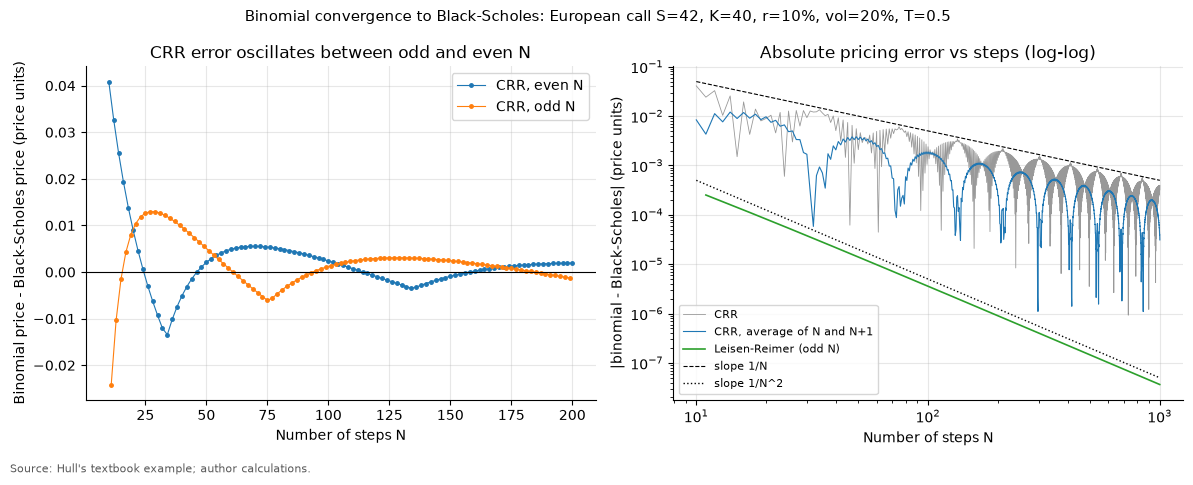

In [5]:
conv = convergence_study()
fig = P.plot_convergence(conv)
bands = {"N 10-100": conv["N"] <= 100, "N 101-1000": conv["N"] > 100}
pd.DataFrame({name: {"CRR": conv.loc[m, "crr_err"].abs().mean(),
                     "CRR, average of N and N+1": conv.loc[m, "crr_avg_N_N1_err"].abs().mean(),
                     "Leisen-Reimer (odd N)": conv.loc[m, "lr_err"].abs().mean()} for name, m in bands.items()}).map(lambda x: f"{x:.2e}")

The CRR error shrinks roughly as 1/N but oscillates, and odd and even N follow two separate curves. The reason is the terminal node grid: odd and even N place the nodes half a step apart in log price, so the strike sits at a different point between two nodes, and that point keeps moving as N grows. Averaging the N and N+1 prices removes the odd/even alternation and cuts the mean error for N = 101 to 1,000 from 6.4e-04 to 2.9e-04; the slower oscillation remains. Leisen-Reimer centres the tree on the strike and converges as 1/N²: with 101 steps it is within 3.5e-06 of Black-Scholes, closer than CRR gets with 1,000 steps (error 3.9e-04).

## 3. Market data: the NSE option chain on 30-Oct-2026

Six expiries were downloaded on 31-Oct-2026 from `https://www.nseindia.com/api/option-chain-v3?type=Indices&symbol=NIFTY&expiry=<date>`. The snapshot timestamp is 30-Oct-2026 15:40 IST, the close of index derivatives trading (extended to 15:40 from 3-Aug-2026). NIFTY options are European and cash-settled. Quotes are filtered in this order:

1. strike within ±10% of spot (23,053.10)
2. open interest > 0
3. two-sided quote: best bid > 0 and best ask > 0
4. bid-ask spread ≤ 25% of the mid, where mid = (best bid + best ask) / 2

In [6]:
chain = apply_quote_filters(load_option_chains(RAW), A.SPOT_CLOSE)
print("snapshot:", chain["snapshot_time"].iloc[0], "| JSON underlyingValue:", chain["chain_underlying"].iloc[0])
assert abs(chain["chain_underlying"].iloc[0] - A.SPOT_CLOSE) < 0.005, "spot mismatch"
qty = pd.concat([chain["bid_qty"], chain["ask_qty"]])
qty = qty[qty > 0]
print(f"quote sizes that are multiples of 65 (the NIFTY lot): {(qty % 65 == 0).mean():.1%}")
filter_summary(chain)

snapshot: 2026-10-30 15:40:00 | JSON underlyingValue: 23053.1
quote sizes that are multiples of 65 (the NIFTY lot): 100.0%


,expiry,days,listed,within_10pct,and_oi_gt_0,and_two_sided_quote,and_spread_le_25pct,usable_calls,usable_puts
0,2026-11-03,4,208,180,171,171,170,84,86
1,2026-11-09,10,208,180,149,149,132,66,66
2,2026-11-17,18,176,176,130,130,97,47,50
3,2026-11-23,24,244,186,180,180,164,74,90
4,2026-12-01,32,106,106,86,86,70,31,39
5,2026-12-29,60,244,180,168,164,140,74,66


Data issues and how they are handled:

- Strikes without a listed contract appear in the JSON as all-zero objects with no identifier; they are dropped.
- The 17-Nov-2026 and 01-Dec-2026 weeklies are the thinnest: only 55% and 66% of their strikes within ±10% survive the filters (no open interest, or a spread above 25%), against 94% for the 03-Nov weekly.
- Open interest in the 29-Dec-2026 file is fractional for 31 contracts (for example 435.23 contracts for the 12,000 put), probably a units conversion after the lot-size change; only the OI > 0 test uses it.
- The 09-Nov and 23-Nov expiries fall on a Monday because Tuesday 10-Nov (Diwali Balipratipada) and Tuesday 24-Nov (Guru Nanak Jayanti) are market holidays; NSE then moves the expiry to the previous trading day.
- Some deep in-the-money quotes have a mid below intrinsic value; they get no implied vol (NaN) and the smile uses out-of-the-money quotes only.

## 4. Implied forwards from put-call parity

For each strike with a usable call and put, $F_K = K + (C_{mid} - P_{mid})\,e^{rT}$. The forward is the median $F_K$ over the five strikes with the smallest $|C - P|$. The quotes also bound it: $F_{low} = K + (C_{bid} - P_{ask})e^{rT}$ and $F_{high} = K + (C_{ask} - P_{bid})e^{rT}$, intersected over the same strikes. Carry $b = \ln(F/S)/T$ and implied yield $q = r - b$ are measured against the official close of 23,053.10. `pv_gap_points` is $S - DF \cdot F$, the present value of whatever separates the forward from $S e^{rT}$.

In [7]:
fwd = A.implied_forwards(chain)
cols = ["expiry", "days", "strikes_used", "F", "F_bidask_low", "F_bidask_high", "F_minus_spot", "carry_b", "q_implied", "pv_gap_points", "F_theory_div_yield"]
display(fwd[cols].assign(expiry=fwd["expiry"].dt.strftime("%d-%b-%Y")).round(4))
f_m = fwd.set_index("expiry").loc[MONTHLY]
print(f"23-Nov-2026 parity forward {f_m['F']:,.2f} vs NIFTY Nov-2026 futures close {A.NOV_FUTURES_CLOSE:,.2f}: "
      f"difference {f_m['F'] - A.NOV_FUTURES_CLOSE:+.2f} points")
assert abs(f_m["F"] / A.NOV_FUTURES_CLOSE - 1) < 0.001

,expiry,days,strikes_used,F,F_bidask_low,F_bidask_high,F_minus_spot,carry_b,q_implied,pv_gap_points,F_theory_div_yield
0,03-Nov-2026,4,22900 22950 23000 23050 23100,23022.1390,23021.6768,23022.8829,-30.9610,-0.1226,0.1802,45.4909,23064.0691
1,09-Nov-2026,10,22950 23000 23050 23100 23150,23048.4553,23047.3747,23048.4187,-4.6447,-0.0074,0.0650,40.9936,23080.5326
2,17-Nov-2026,18,22950 23000 23050 23100 23150,23074.3441,23072.7728,23074.4612,21.2441,0.0187,0.0389,44.2161,23102.5023
3,23-Nov-2026,24,23000 23050 23100 23150 23200,23097.2898,23096.3361,23097.3681,44.1898,0.0291,0.0285,43.1360,23118.9932
4,01-Dec-2026,32,23050 23100 23150 23200 23250,23127.1637,23120.6000,23132.4095,74.0637,0.0366,0.0210,42.4476,23140.9994
5,29-Dec-2026,60,23150 23200 23250 23300 23350,23241.2387,23237.4530,23245.0244,188.1387,0.0494,0.0082,30.9138,23218.1863


23-Nov-2026 parity forward 23,097.29 vs NIFTY Nov-2026 futures close 23,101.40: difference -4.11 points


What the forwards say:

- The 23-Nov-2026 forward is 23,097.29, 4.1 points below the NIFTY November futures close of 23,101.40 reported by Capital Market. Options and futures agree.
- Read as a dividend yield against the official close, the forwards do not make sense: the 4-day forward is 31 points below spot (implied q = 18.0%), while the 60-day one implies q = 0.8%. The PV gap is 41-45 points for every expiry up to 32 days and 31 points at 60 days. That looks like a fixed offset between the official close and the level at which the derivatives market valued the index, not a yield. Possible reasons: dividends going ex in early November, the closing auction for F&O stocks (introduced 3-Aug-2026, 15:15-15:35) that sets the official close while index options trade until 15:40, and futures basis below cost of carry. One snapshot cannot separate them.
- Spot with the 1.42% dividend yield from the NIFTY 50 factsheet of 30-Oct-2026 would put the 23-Nov forward at 23,119, 22 points too high. Pricing on the parity forward (Black-76) avoids that error, and BSM with q = r − ln(F/S)/T gives identical prices with spot-based Greeks.

## 5. Implied volatilities and the 23-Nov-2026 smile

Own IVs use the mid price, Black-76 on the parity forward of each expiry and the T-bill discount factor. IVs at the bid and the ask show how much of the smile is quote noise. NSE's `impliedVolatility` field is shown for comparison. The smile uses out-of-the-money options: puts below the forward, calls above it.

usable quotes 773, with a valid IV 729 (Newton 729, Brent 0)


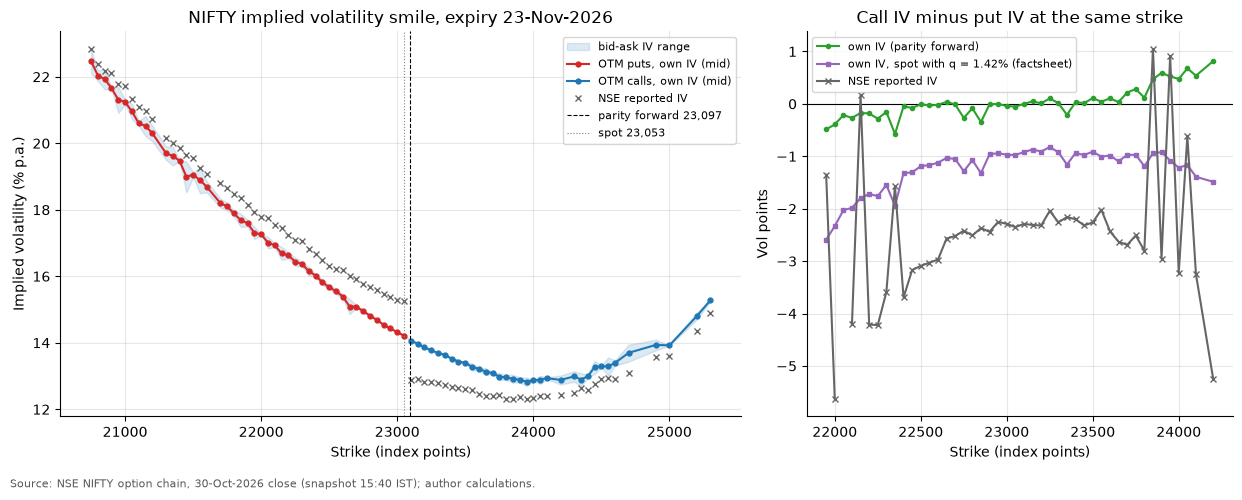

In [8]:
r_nse, nse_tab = A.nse_iv_convention(chain)
ivs = A.add_implied_vols(chain, fwd, r_nse=r_nse)
usable = ivs[ivs["usable"]]
print(f"usable quotes {len(usable)}, with a valid IV {usable['iv'].notna().sum()} "
      f"(Newton {(usable['iv_method'] == 0).sum()}, Brent {(usable['iv_method'] == 1).sum()})")
smile = A.otm_smile(ivs, MONTHLY)
gap = A.call_put_iv_gap(ivs, MONTHLY)
fig = P.plot_smile(smile, gap, "23-Nov-2026", f_m["F"], A.SPOT_CLOSE)

In [9]:
atm = A.interp_iv(smile, 1.0)
iv90, iv95, iv105 = (A.interp_iv(smile, m) for m in (0.90, 0.95, 1.05))
nse_atm = A.interp_iv(smile.assign(iv=smile["iv_nse"]), 1.0)
print(f"ATM IV (K = F) {atm:.2%} | NSE field at K = F {nse_atm:.2%}")
print(f"IV at K/F = 0.90: {iv90:.2%} | 0.95: {iv95:.2%} | 1.05: {iv105:.2%} | skew 95%-105%: {100 * (iv95 - iv105):.2f} vol points")
near = gap[(gap["fwd_moneyness"] - 1).abs() <= 0.02]
print("mean |call IV - put IV| at the same strike, within 2% of F (vol points): "
      f"own {100 * near['gap_own'].abs().mean():.2f}, spot with q = {A.DIV_YIELD_FACTSHEET:.2%} {100 * near['gap_spot_div'].abs().mean():.2f}, "
      f"NSE field {100 * near['gap_nse'].abs().mean():.2f}")
rep = (usable["iv_nse_replica"] - usable["iv_nse"]).abs()
print(f"NSE field reproduced by BSM on the last price with spot, q = 0, r = {r_nse:.2%}: median |difference| {100 * rep.median():.4f} vol points")
cols = ["strike", "option_type", "fwd_moneyness", "bid", "ask", "mid", "iv", "iv_bid", "iv_ask", "iv_nse"]
smile.loc[smile["strike"] % 500 == 0, cols].round(4)

ATM IV (K = F) 14.07% | NSE field at K = F 13.01%
IV at K/F = 0.90: 22.14% | 0.95: 17.35% | 1.05: 12.94% | skew 95%-105%: 4.41 vol points
mean |call IV - put IV| at the same strike, within 2% of F (vol points): own 0.08, spot with q = 1.42% 1.00, NSE field 2.31
NSE field reproduced by BSM on the last price with spot, q = 0, r = 6.39%: median |difference| 0.0026 vol points


,strike,option_type,fwd_moneyness,bid,ask,mid,iv,iv_bid,iv_ask,iv_nse
5,21000.0,P,0.9092,19.10,19.80,19.450,0.2124,0.2117,0.2132,0.2171
14,21500.0,P,0.9308,33.65,34.85,34.250,0.1905,0.1897,0.1913,0.1957
23,22000.0,P,0.9525,68.00,68.45,68.225,0.1726,0.1724,0.1728,0.1779
33,22500.0,P,0.9741,140.30,142.30,141.300,0.1567,0.1562,0.1572,0.1631
43,23000.0,P,0.9958,289.40,290.70,290.050,0.1432,0.1429,0.1435,0.1528
53,23500.0,C,1.0174,156.95,157.00,156.975,0.1340,0.1340,0.1340,0.1261
63,24000.0,C,1.0391,46.90,47.05,46.975,0.1287,0.1287,0.1288,0.1233
71,24500.0,C,1.0607,13.60,13.85,13.725,0.1329,0.1327,0.1331,0.1290
76,25000.0,C,1.0824,3.95,4.00,3.975,0.1392,0.1391,0.1393,0.1359


Reading the smile:

- ATM IV for 23-Nov-2026 is 14.07%. Puts at 95% of the forward trade at 17.35% and calls at 105% at 12.94%, a skew of 4.41 vol points; 90% puts are at 22.14%. The curve bottoms near 23,950 (12.83%) and turns up in the far call wing.
- Why OTM puts are richer: index returns have a fat left tail and volatility jumps when the market falls, so a crash hurts a put writer twice and delta hedging cannot remove gap risk. Institutions also buy index puts as portfolio protection, while overwriting strategies sell upside calls. Writers charge for the downside risk, and the put wing carries it.
- NSE's field differs from my IVs by 1.57 vol points on average, with call IVs lower and put IVs higher at the same strike (2.31 vol points apart near the money). The field is reproduced almost exactly by BSM on the last traded price with spot, no dividends and r ≈ 6.39%. That implies a 23-Nov forward of about 23,150, 53 points above the market forward. With the parity forward, call and put IVs agree within 0.08 vol points; spot with the 1.42% factsheet yield still leaves 1.00 vol points.

## 6. ATM term structure and India VIX

India VIX is NSE's 30-day volatility index, computed from near- and next-month NIFTY option quotes with the CBOE variance formula. Below: (a) ATM IV for each expiry, (b) the same CBOE formula applied to each expiry's strip of two-sided OTM quotes, $\sigma^2 = \frac{2}{T}\sum_i \frac{\Delta K_i}{K_i^2} e^{rT} Q(K_i) - \frac{1}{T}\left(\frac{F}{K_0} - 1\right)^2$, and (c) both interpolated in total variance to 30 days from the two monthly expiries (23-Nov, 24 days; 29-Dec, 60 days).

,expiry,days,F,atm_iv,iv_95,iv_105,skew_95_105,model_free_vol,model_free_strikes,model_free_K_range
0,03-Nov-2026,4,23022.1390,0.1203,0.2302,0.1854,0.0449,0.1363,104,20050-25200
1,09-Nov-2026,10,23048.4553,0.1389,0.1865,0.1458,0.0407,0.1513,104,20050-25200
2,17-Nov-2026,18,23074.3441,0.1389,0.1740,0.1319,0.0421,0.1480,88,20850-25200
3,23-Nov-2026,24,23097.2898,0.1407,0.1735,0.1294,0.0441,0.1523,122,20050-26100
4,01-Dec-2026,32,23127.1637,0.1376,0.1673,0.1256,0.0417,0.1458,77,20850-24700
5,29-Dec-2026,60,23241.2387,0.1372,0.1587,0.1247,0.0339,0.1442,96,20950-34500


30-day ATM IV 13.95% | 30-day model-free vol 14.96% | India VIX 15.30 | 21-day realised vol 14.69%


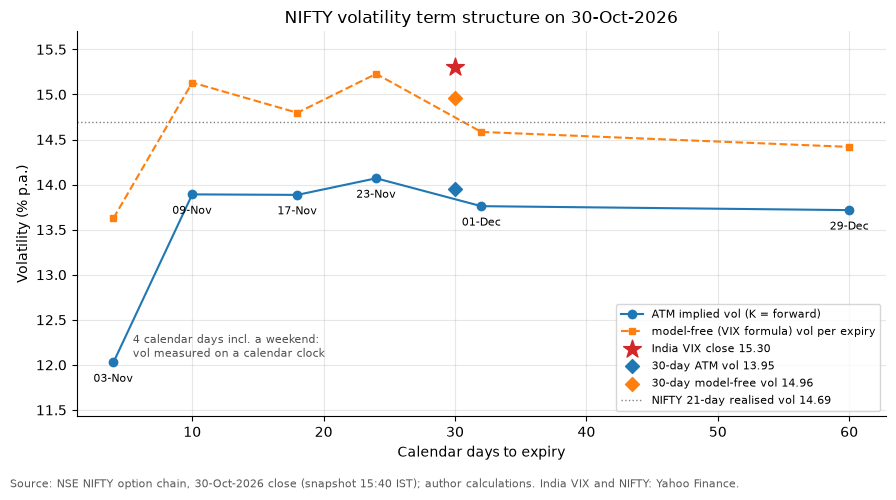

In [10]:
ts = A.atm_term_structure(ivs, fwd)
tsi = ts.set_index("expiry")
atm30 = A.interpolate_vol_30d(tsi.loc[MONTHLY, "T"], tsi.loc[MONTHLY, "atm_iv"], tsi.loc[NEXT_MONTHLY, "T"], tsi.loc[NEXT_MONTHLY, "atm_iv"])
mf30 = A.interpolate_vol_30d(tsi.loc[MONTHLY, "T"], tsi.loc[MONTHLY, "model_free_vol"], tsi.loc[NEXT_MONTHLY, "T"], tsi.loc[NEXT_MONTHLY, "model_free_vol"])
vr = A.vix_vs_realised(load_index_history(RAW / "IDX_INDIAVIX.csv"), load_index_history(RAW / "IDX_NSEI.csv"))
rv21 = vr["rv_trailing"].iloc[-1] / 100
ts_cols = ["expiry", "days", "F", "atm_iv", "iv_95", "iv_105", "skew_95_105", "model_free_vol", "model_free_strikes", "model_free_K_range"]
display(ts[ts_cols].assign(expiry=ts["expiry"].dt.strftime("%d-%b-%Y")).round(4))
print(f"30-day ATM IV {atm30:.2%} | 30-day model-free vol {mf30:.2%} | India VIX {A.INDIA_VIX:.2f} | 21-day realised vol {rv21:.2%}")
fig = P.plot_term_structure(ts, A.INDIA_VIX, atm30, mf30, rv21)

India VIX minus NIFTY realised vol over the next 21 trading days: mean +2.06 vol points, positive on 77% of 1228 days (Oct-2021 to Sep-2026)


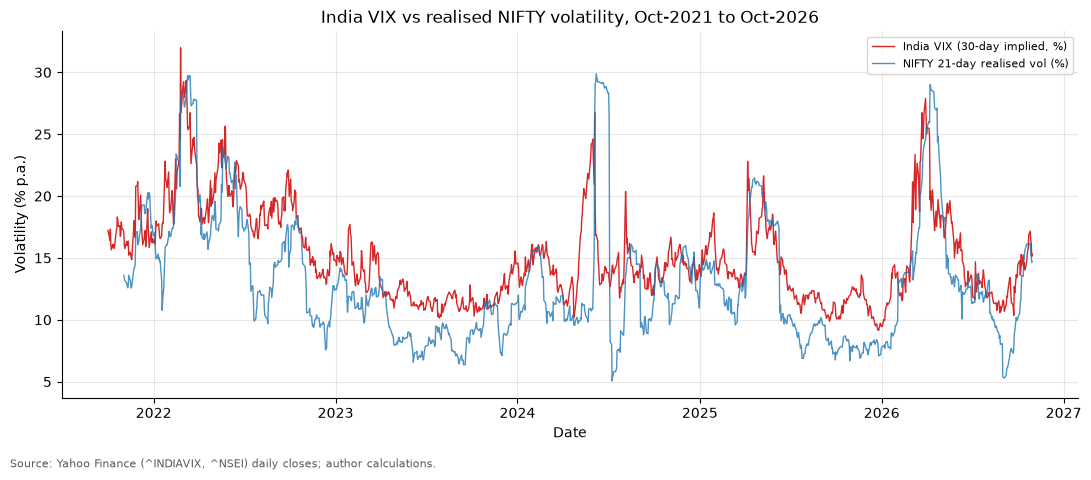

In [11]:
vrp = (vr["vix"] - vr["rv_next"]).dropna()
print(f"India VIX minus NIFTY realised vol over the next 21 trading days: mean {vrp.mean():+.2f} vol points, "
      f"positive on {(vrp > 0).mean():.0%} of {len(vrp)} days ({vrp.index.min():%b-%Y} to {vrp.index.max():%b-%Y})")
fig = P.plot_vix_history(vr)

- ATM IV is flat at 13.7%-14.1% from 10 to 60 days. The 4-day expiry shows 12.0%, but its 4 calendar days include a weekend, so at most two trading sessions remain; measured on a trading-day clock its vol would be higher.
- The 30-day ATM IV of 13.95% is below India VIX (15.30). The difference is the skew: the VIX formula integrates the whole OTM strip, so expensive OTM puts lift it above ATM vol. The same formula on these quotes gives 14.96%, 0.34 vol points below the published index (my strike cut-off, forward and rate differ from NSE's inputs).
- Trailing 21-day realised vol is 14.69%. Over Oct-2021 to Sep-2026, India VIX exceeded the realised vol of the following 21 trading days by 2.06 vol points on average and on 77% of days: option buyers usually pay a volatility risk premium.

## 7. Greeks of market contracts (23-Nov-2026)

Contracts: the ATM call and put at the listed strike closest to the forward, and the put closest to 95% of spot. Greeks are BSM spot Greeks at each contract's own IV, with q set to the expiry's implied yield so that model prices equal the mid quotes. The CRR columns repeat the calculation on a 1,000-step tree. Per-lot rupee values use the lot size of 65 (1 index point = ₹1 per unit).

In [12]:
m_strikes = usable.loc[usable["expiry"] == MONTHLY, "strike"].drop_duplicates()
k_atm = float(m_strikes.iloc[(m_strikes - f_m["F"]).abs().argmin()])
k_otm = float(m_strikes.iloc[(m_strikes - 0.95 * A.SPOT_CLOSE).abs().argmin()])
contracts = [{"label": "ATM call", "expiry": MONTHLY, "strike": k_atm, "option_type": "C"},
             {"label": "ATM put", "expiry": MONTHLY, "strike": k_atm, "option_type": "P"},
             {"label": "5% OTM put", "expiry": MONTHLY, "strike": k_otm, "option_type": "P"}]
gt = A.greeks_table(contracts, ivs, fwd)
show = ["strike", "mid", "iv_own", "iv_nse", "delta", "gamma", "vega_per_volpt", "theta_per_day", "rho_per_pct",
        "tree_delta", "tree_gamma", "tree_vega_per_volpt", "tree_theta_per_day", "premium_per_lot_rs", "vega_per_lot_rs", "theta_per_lot_rs"]
gt.set_index("label")[show].T.map(lambda x: f"{x:,.6g}")

label,ATM call,ATM put,5% OTM put
strike,"23,100","23,100","21,900"
mid,329.65,332.35,59.1
iv_own,0.140617,0.140617,0.175952
iv_nse,0.1288,0.1517,0.1813
delta,0.504947,-0.493181,-0.114407
gamma,0.000478985,0.000478985,0.000185829
vega_per_volpt,23.5363,23.5363,11.4258
theta_per_day,-7.77182,-5.93536,-3.96855
rho_per_pct,7.43734,-7.69427,-1.77306
tree_delta,0.504932,-0.493198,-0.114304


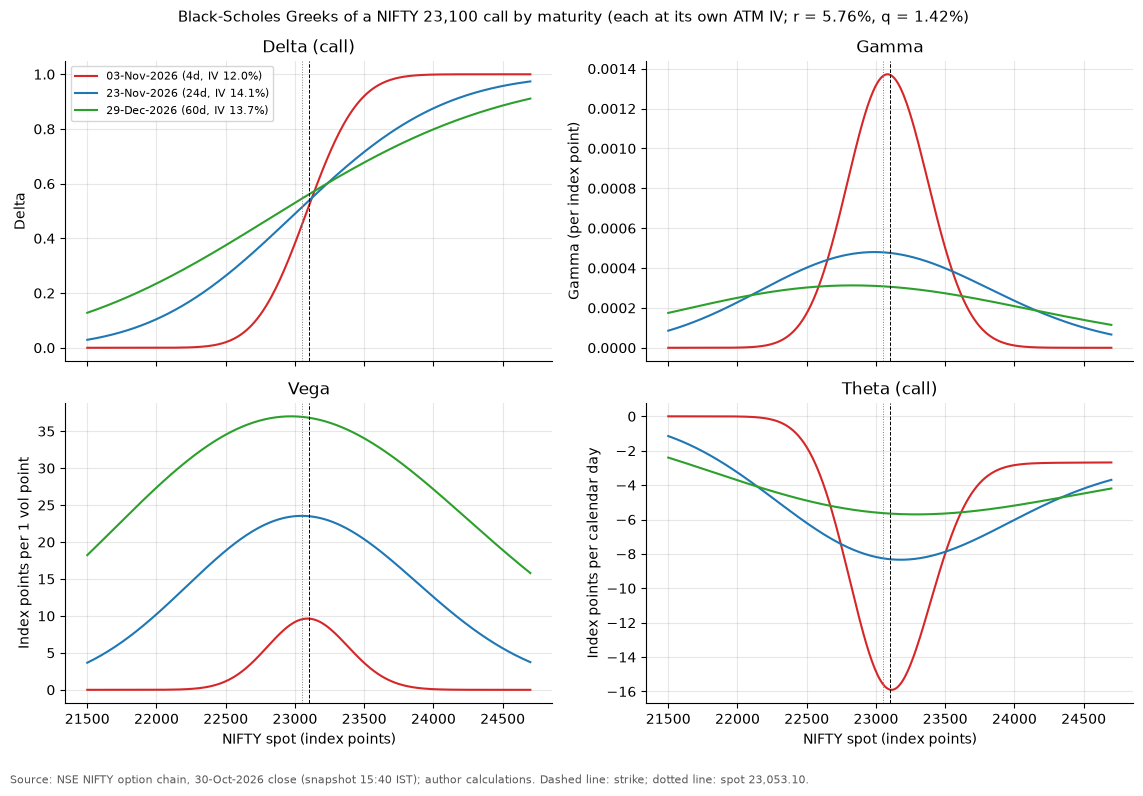

In [13]:
mats = [{"label": f"{e:%d-%b-%Y} ({int(tsi.loc[e, 'days'])}d, IV {100 * tsi.loc[e, 'atm_iv']:.1f}%)",
         "T": tsi.loc[e, "T"], "sigma": tsi.loc[e, "atm_iv"], "q": A.DIV_YIELD_FACTSHEET}
        for e in (pd.Timestamp("2026-11-03"), MONTHLY, NEXT_MONTHLY)]
prof = A.greek_profiles(np.arange(21500.0, 24701.0, 10.0), k_atm, mats)
fig = P.plot_greek_profiles(prof, k_atm, A.SPOT_CLOSE)

- The ATM call (23,100) costs 329.65 points, or ₹21,427 per lot. Delta 0.505, gamma 0.00048 per point, vega 23.5 points per vol point (₹1,530 per lot) and theta -7.77 points per day (₹-505 per lot).
- The put at the same strike has the same gamma and vega. Its theta is smaller in size (-5.94) because parity ties the two: θ_call − θ_put = qSe^(−qT) − rKe^(−rT), which is -1.84 points per day at r = 5.76% and q = 2.85%.
- The 5% OTM put (21,900) costs 59.10 points at 17.6% IV, with delta -0.114 and theta -3.97 points per day: 6.7% of its price per day, against 2.4% for the ATM call.
- Tree Greeks (1,000 steps) agree with the formulas within 0.09% for delta, gamma, theta and rho and within 0.5% for vega, which the tree gets by bumping the volatility.
- The profiles show what happens as expiry nears: gamma and theta concentrate around the strike (peak gamma 0.00137 per point at 4 days against 0.00048 at 24 days) and vega shrinks with the square root of time.

## 8. Binomial trees on market contracts, and an American-style put

All 79 OTM contracts of the 23-Nov-2026 smile are priced with BSM, CRR (N = 1,000) and Leisen-Reimer (N = 501), each at its own IV with S = 23,053.10 and q = the implied yield. NIFTY options are European, so the American put below is a what-if on the same terms.

In [14]:
q_m = float(f_m["q_implied"])
bvb = A.binomial_vs_bs(smile, q_m)
print(f"{len(bvb)} contracts: max |BSM - mid| {bvb['bs_minus_mid'].abs().max():.1e} | "
      f"max |CRR - BSM| {bvb['crr_minus_bs'].abs().max():.4f} pts | max |LR - BSM| {bvb['lr_minus_bs'].abs().max():.6f} pts | "
      f"median bid-ask spread {(smile['ask'] - smile['bid']).median():.2f} pts")
prem = A.american_put_premium(np.arange(21500.0, 24751.0, 250.0), smile, float(f_m["T"]), q_m)
prem.round(4)

79 contracts: max |BSM - mid| 3.8e-12 | max |CRR - BSM| 0.0791 pts | max |LR - BSM| 0.000068 pts | median bid-ask spread 2.00 pts


,strike,strike_over_spot,iv,bs_european,crr_european,crr_american,early_exercise_premium,premium_pct_of_european
0,21500.0,0.9326,0.1905,34.2500,34.2618,34.3973,0.1355,0.3954
1,21750.0,0.9435,0.1810,47.7000,47.6869,47.9021,0.2152,0.4512
2,22000.0,0.9543,0.1726,68.2250,68.2433,68.5923,0.3490,0.5114
3,22250.0,0.9652,0.1644,97.9750,98.0041,98.5793,0.5752,0.5869
4,22500.0,0.9760,0.1567,141.3000,141.3643,142.3330,0.9688,0.6853
5,22750.0,0.9869,0.1495,203.1000,203.1771,204.8215,1.6444,0.8093
6,23000.0,0.9977,0.1432,290.0500,289.9709,292.7908,2.8199,0.9725
7,23250.0,1.0085,0.1377,406.8579,406.8745,411.6159,4.7414,1.1653
8,23500.0,1.0194,0.1340,558.1627,558.1613,565.9680,7.8067,1.3987
9,23750.0,1.0302,0.1298,737.6925,737.6741,750.2688,12.5947,1.7074


1-year put, q = 0 | S*/K at 1y, 6m, 3m, 1m to expiry: 0.891, 0.905, 0.920, 0.944
1-year put, q = 1.42% (factsheet yield) | S*/K at 1y, 6m, 3m, 1m to expiry: 0.875, 0.895, 0.913, 0.940
perpetual put limit (q = 0): S*/K = 2r/(2r + vol^2) = 0.853


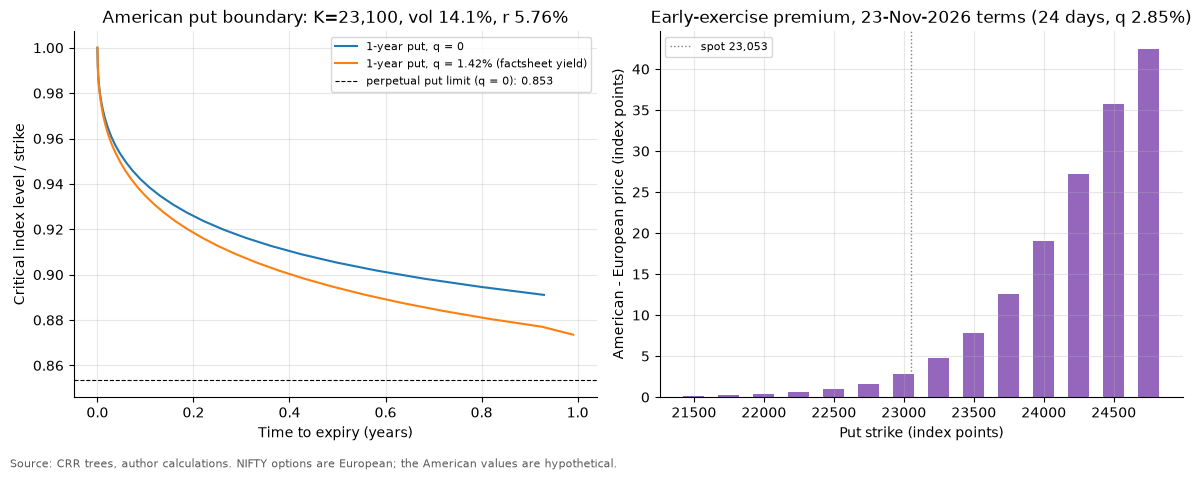

In [15]:
bnd = {f"1-year put, {lab}": early_exercise_boundary(0.9 * k_atm, k_atm, 1.0, A.R_CONT, atm, qq, "put", N=5000)
       for qq, lab in ((0.0, "q = 0"), (A.DIV_YIELD_FACTSHEET, f"q = {A.DIV_YIELD_FACTSHEET:.2%} (factsheet yield)"))}
perpetual = 2 * A.R_CONT / (2 * A.R_CONT + atm**2)
for lab, b in bnd.items():
    bb = b.dropna()
    at = {tau: bb.loc[(bb["tau"] - tau).abs().idxmin(), "boundary_over_K"] for tau in (1.0, 0.5, 0.25, 1 / 12)}
    print(lab, "| S*/K at 1y, 6m, 3m, 1m to expiry:", ", ".join(f"{v:.3f}" for v in at.values()))
print(f"perpetual put limit (q = 0): S*/K = 2r/(2r + vol^2) = {perpetual:.3f}")
fig = P.plot_early_exercise(bnd, perpetual, prem, A.SPOT_CLOSE,
                            title_left=f"American put boundary: K={k_atm:,.0f}, vol {100 * atm:.1f}%, r {100 * A.R_CONT:.2f}%",
                            title_right=f"Early-exercise premium, 23-Nov-2026 terms ({int(f_m['days'])} days, q {100 * q_m:.2f}%)")

- Leisen-Reimer reproduces every Black-Scholes price within 0.0001 points and CRR within 0.08 points, against a median bid-ask spread of about 2 points. For European options the tree adds nothing but cost; it earns its keep when exercise can happen early.
- With r (5.76%) above q (2.85%), an American put on 23-Nov-2026 terms is worth more than the European one: 2.8 points at the 23,000 strike (about 1%) and 42.5 points at 24,750, where exercising at once is optimal (American value 1,696.90 = intrinsic, against a European value of 1,654.40). Puts more than 2% out of the money gain less than 1 point.
- The boundary: a 1-year put with q = 0 should be exercised once the index falls below 0.891 × K; the critical level rises to K at expiry and stays above the perpetual limit of 0.853 × K. A dividend yield lowers it (0.875 × K with q = 1.42%), because the holder of the put benefits from the index drifting down by its dividends while waiting.

## 9. Delta-hedging simulation

A writer sells one 23,100 call to 23-Nov-2026 at its model value (IV of the ATM call), holds the Black-Scholes delta in the index, rebalances at equal intervals, finances at r and receives q on the units held. Index paths follow geometric Brownian motion; 20,000 paths, seed 42, no transaction costs.

,rebalances,mean_pts,std_pts,p05_pts,p95_pts,std_pct_of_premium,std_per_lot_rs
0,6,-1.77,112.65,-192.72,177.05,34.17,7322.11
1,12,-0.90,80.56,-134.89,129.90,24.44,5236.72
2,24,-0.28,57.45,-93.56,93.14,17.43,3733.96
3,48,-0.20,41.32,-68.08,66.32,12.54,2686.07
4,96,0.07,29.92,-49.54,48.76,9.08,1944.70
5,192,-0.02,20.83,-34.26,33.61,6.32,1354.18
6,384,0.08,14.83,-24.27,24.14,4.50,963.66


,sigma_implied,sigma_real,mean_pts,std_pts,mean_per_lot_rs
0,0.1406,0.1000,95.3512,50.3812,6197.8252
1,0.1406,0.1406,-0.2761,57.4455,-17.9485
2,0.1406,0.1800,-92.8761,83.4323,-6036.9456


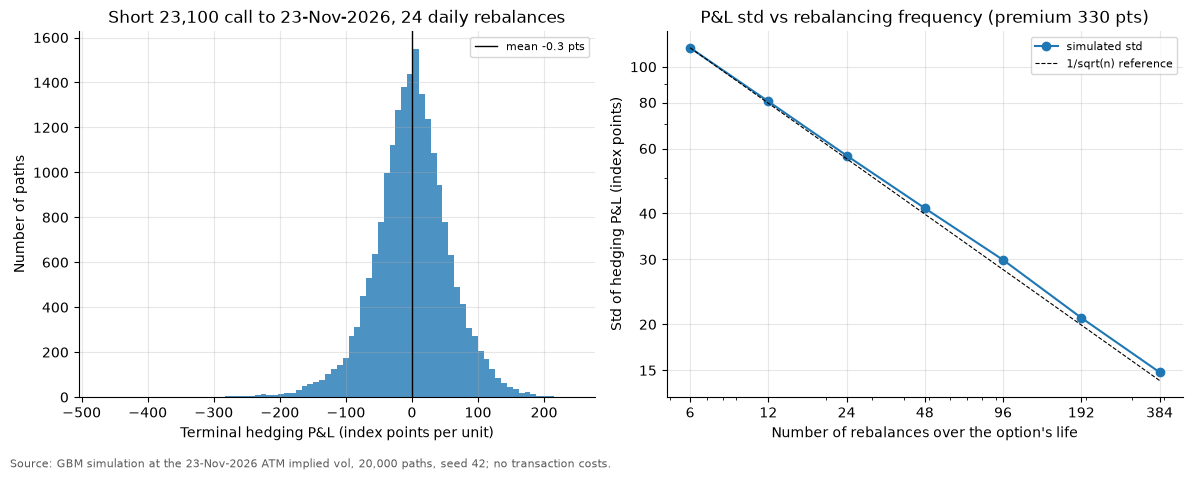

In [16]:
iv_c = float(gt.loc[gt["label"] == "ATM call", "iv_own"].iloc[0])
T_m = float(f_m["T"])
hedge = hedge_experiment(A.SPOT_CLOSE, k_atm, T_m, A.R_CONT, q_m, iv_c, steps_list=(6, 12, 24, 48, 96, 192, 384))
display(hedge[["rebalances", "mean_pts", "std_pts", "p05_pts", "p95_pts", "std_pct_of_premium", "std_per_lot_rs"]].round(2))
vol_mismatch = hedge_experiment(A.SPOT_CLOSE, k_atm, T_m, A.R_CONT, q_m, iv_c, steps_list=(24,), real_vols=(0.10, iv_c, 0.18))
display(vol_mismatch[["sigma_implied", "sigma_real", "mean_pts", "std_pts", "mean_per_lot_rs"]].round(4))
pnl = simulate_delta_hedge(A.SPOT_CLOSE, k_atm, T_m, A.R_CONT, q_m, iv_c, None, 24, 20000, 42)
fig = P.plot_hedging(pnl, hedge, float(hedge["premium_pts"].iloc[0]), label=f"Short {k_atm:,.0f} call to 23-Nov-2026, 24 daily rebalances")

- When realised vol equals implied vol, the hedge has a mean P&L near zero (-0.3 points with daily rebalancing) and its standard deviation falls with the square root of the number of rebalances: 113 points with 6, 57 with 24 (daily), 15 with 384. Daily hedging still leaves a standard deviation of 17% of the 330-point premium.
- If the index realises 18% instead of 14.06%, the short call loses 93 points on average (₹6,037 per lot); at 10% it earns 95 points. Delta hedging removes direction, not volatility: the writer is short gamma and collects theta, and the result depends on realised against implied variance.

## 10. Regenerate all outputs and cross-check

`src/run_all.py` repeats the steps above and writes `figures/*.png`, `outputs/*.csv` and `data/nifty_options_2026-10-30.csv`. Its validation table adds the market checks (forward vs futures, quote consistency, IV coverage, tree accuracy on market contracts, NSE field replication, VIX replication).

In [17]:
import run_all

res = run_all.run(verbose=False)
v = res["validation"]
print_checks(v)
assert (v["status"] == "PASS").all(), "a check failed"
head = res["headline"].set_index("key")["value"]
assert np.isclose(float(head["atm_iv_23nov"]), atm) and np.isclose(float(head["forward_23nov"]), f_m["F"])
assert np.isclose(float(head["model_free_vol_30d"]), mf30) and np.isclose(float(head["atm_iv_30d_monthlies"]), atm30)
print("figures:", ", ".join(sorted(p.name for p in (ROOT / "figures").glob("*.png"))))
print("outputs:", ", ".join(sorted(p.name for p in (ROOT / "outputs").glob("*.csv"))))

PASS | BSM            | Hull example call price (S=42, K=40, r=10%, vol=20%, T=0.5)    | value 4.75942      | target 4.76 (2 dp)
PASS | BSM            | Hull example put price                                         | value 0.808599     | target 0.81 (2 dp)
PASS | Parity         | max |C - P - (S e^-qT - K e^-rT)|, 10,000 random contracts     | value 7.10543e-14  | target < 1e-10
PASS | Greeks         | Hull example: max |analytic - finite difference| (5 Greeks, call+put, q=0 and 3%) | value 4.53795e-07  | target < 1e-4
PASS | Greeks         | NIFTY-size contract: max relative |analytic - finite difference| | value 3.51481e-06  | target < 1e-4
PASS | Implied vol    | Newton solver recovers input vol (1606 identifiable contracts) | value 4.79451e-09  | target < 1e-8
PASS | Implied vol    | Brent fallback recovers input vol (Newton capped at 1 step, 179 contracts) | value 7.23035e-10  | target < 1e-8
PASS | Implied vol    | prices outside no-arbitrage bounds return NaN (5 cases)        |